# L6 RG: D128 continuation and matched convergence diagnostics

All **456** cases are planned at D128, continuing **both saved D64 starts**, including cases previously qualified.
Parameters remain $L=6$, $N=108$, $m=6$, $\chi=8$, $h=0.15$, $K_{ij}\sim U(0.5,1.5)$,
$\Gamma=0.100:0.025:1.500$, disorders 60000–60007. The original optimizer and numerical tolerances are retained.

**This is a dated local snapshot. Coverage below determines which comparisons are available.**
Missing cases are not zeroes or solver failures. All completed cases, including unqualified ones, are plotted.
Starts remain separate; error ribbons are disorder-only standard errors and require all eight disorders.
The full D64 evidence remains in `triangle_L6_m6_chi8_D64_convergence.ipynb`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'code/transformer_qmc/l6_d128_diagnostics.py').exists())
sys.path.insert(0,str(ROOT/'code'))
from transformer_qmc.l6_d128_diagnostics import analyze, DATA128
records, comparisons, cases, summary=analyze(ROOT)
FIG=ROOT/'figures/triangle_L6_m6_chi8_D128_convergence'
FIG.mkdir(parents=True,exist_ok=True)
gammas=np.arange(100,1501,25)/1000
ids=list(range(60000,60008))
colors={0:'#0072B2',1:'#D55E00'}
styles={32:':',64:'--',128:'-'}
plt.rcParams.update({'figure.dpi':110,'font.size':10})
def finish(fig,name):
    fig.savefig(FIG/(name+'.png'),bbox_inches='tight',dpi=160)
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    plt.show();plt.close(fig)
stamp=pd.Timestamp(summary['snapshot']['utc'],unit='s',tz='UTC')
display(Markdown(f"**Snapshot: {stamp}. Completed and locally verified: {summary['completed']}/456 cases. "
                 f"Full solver qualification: {summary['qualified']}; q_EA checks pass: {summary['q_pass']}.**"))
display(Markdown('Every completed case has six records: two starts × D32/D64/D128. '
                 'Input-state ancestry, NPZ hashes, matching couplings, physical moments and qualification decisions are checked.'))

**Snapshot: 2026-11-06 00:00:34.661851645+00:00. Completed and locally verified: 0/456 cases. Full solver qualification: 0; q_EA checks pass: 0.**

Every completed case has six records: two starts × D32/D64/D128. Input-state ancestry, NPZ hashes, matching couplings, physical moments and qualification decisions are checked.

## Coverage and qualification

Grey cells are missing from this snapshot. Blue means full qualification; gold means q_EA passes while another check fails;
red means q_EA fails. Qualification compares D64→D128 in each start and the two D128 endpoints.
The previous D64 truncation alarm remains part of the ladder check.

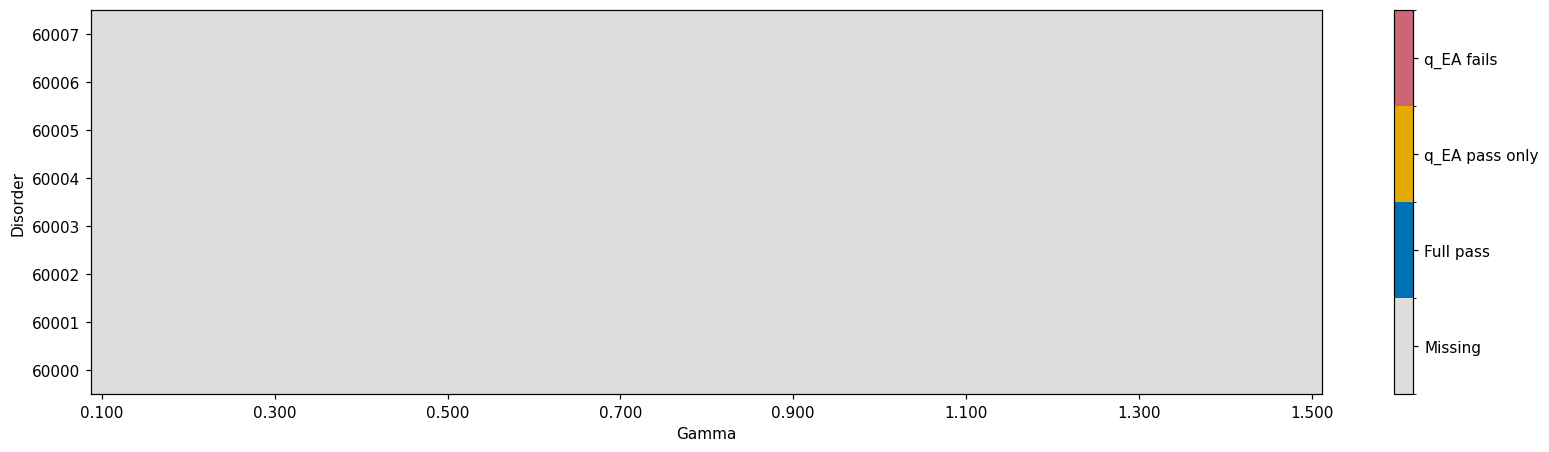

In [2]:
from matplotlib.colors import ListedColormap, BoundaryNorm
grid=pd.DataFrame(-1,index=ids,columns=gammas)
for r in cases.itertuples():grid.loc[r.sample_id,r.gamma]=0 if r.solver_passed else (1 if r.q_pass else 2)
fig,ax=plt.subplots(figsize=(14,4),layout='constrained')
im=ax.imshow(grid,aspect='auto',origin='lower',cmap=ListedColormap(['#dddddd','#0072B2','#E6AB02','#CC6677']),norm=BoundaryNorm([-1.5,-.5,.5,1.5,2.5],4))
ticks=np.arange(0,57,8)
ax.set(xticks=ticks,xticklabels=[f'{gammas[i]:.3f}' for i in ticks],yticks=range(8),yticklabels=ids,xlabel='Gamma',ylabel='Disorder')
cb=fig.colorbar(im,ax=ax,ticks=[-1,0,1,2]);cb.ax.set_yticklabels(['Missing','Full pass','q_EA pass only','q_EA fails'])
finish(fig,'01_coverage')

## Individual disorders and both starts

Each panel shows only cases with both D128 starts complete. Lines are broken at missing fields.
Markers keep isolated points visible. Individual disorders have no error bars.

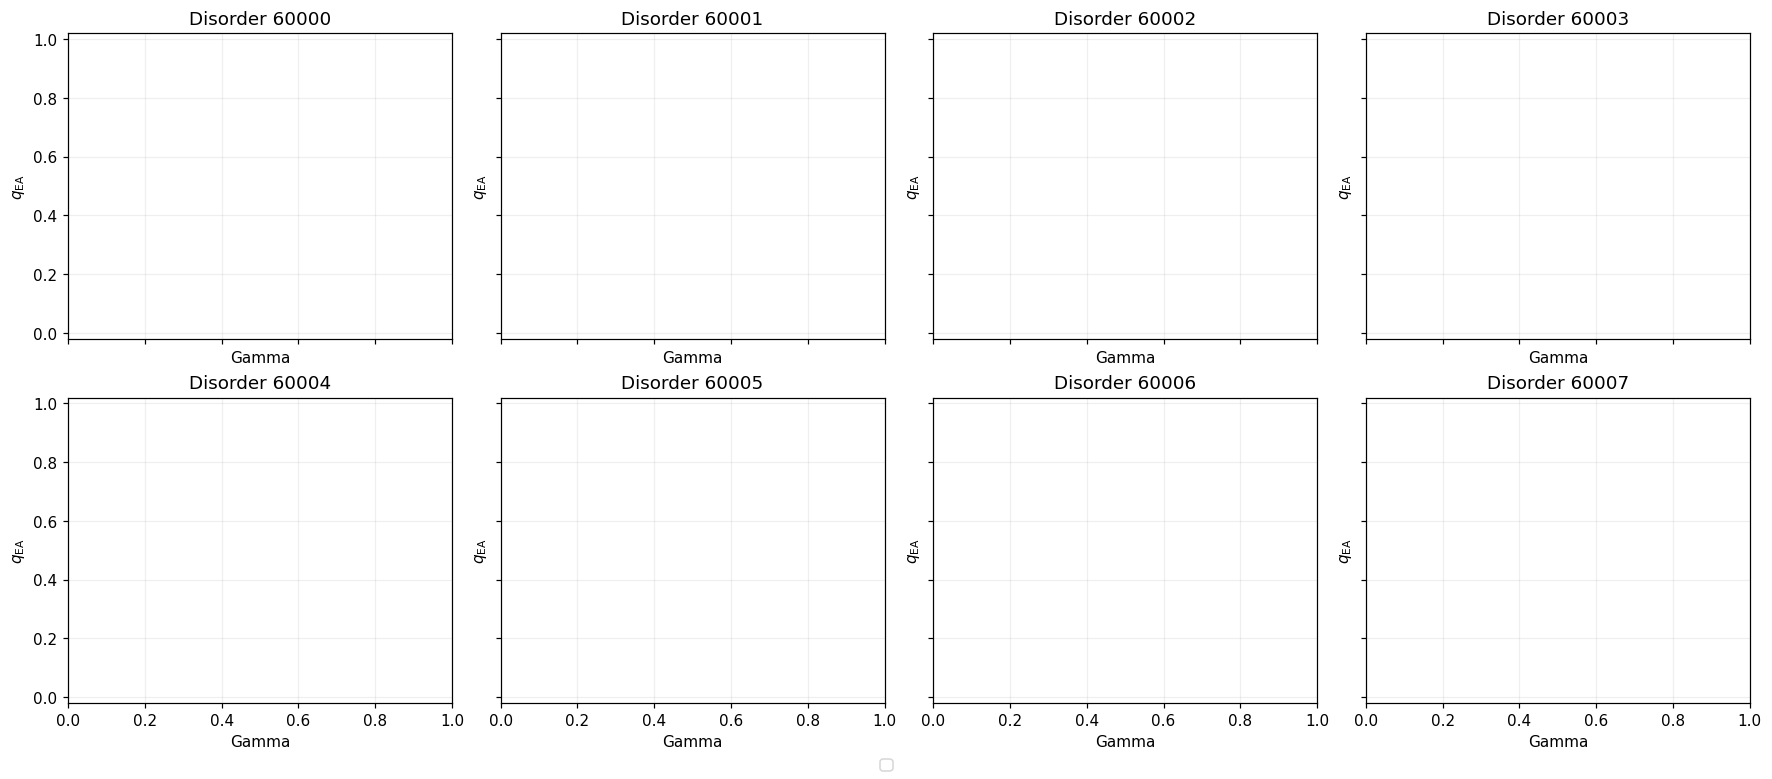

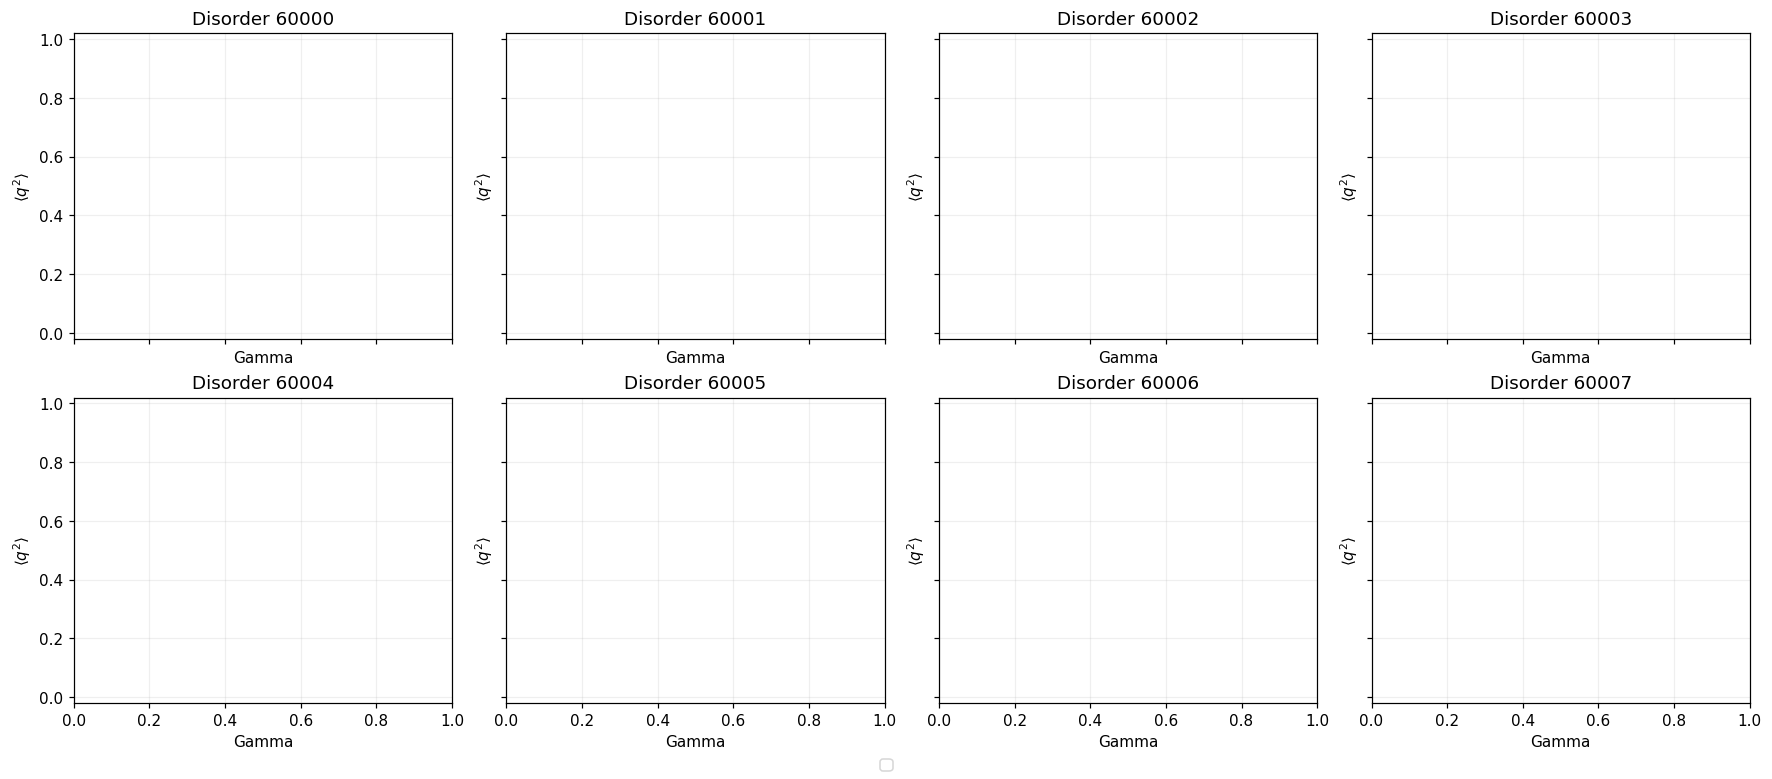

In [3]:
for key,label,filename in [('q_ea_finite',r'$q_{\rm EA}$','02_individual_qEA'),('q2_raw',r'$\langle q^2\rangle$','03_individual_q2')]:
    fig,axes=plt.subplots(2,4,figsize=(16,7),sharex=True,sharey=True,layout='constrained')
    for ax,sid in zip(axes.flat,ids):
        for seed in (0,1):
            for dim in (32,64,128):
                if len(records):
                    a=records[(records.sample_id==sid)&(records.seed==seed)&(records.D_MPS==dim)].set_index('gamma')[key].reindex(gammas)
                    ax.plot(gammas,a,color=colors[seed],ls=styles[dim],marker='o' if dim==128 else '.',ms=3,label=f'start {seed}, D={dim}')
        ax.set(title=f'Disorder {sid}',xlabel='Gamma',ylabel=label,ylim=(-.02,1.02));ax.grid(alpha=.2)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='outside lower center',ncol=6)
    finish(fig,filename)

## Disorder means on fully matched fields

Means and ± one standard error use the same eight disorders at each dimension, separately for each start.
Fields without all eight completed D128 cases are omitted. Solver failures remain in these diagnostic curves.

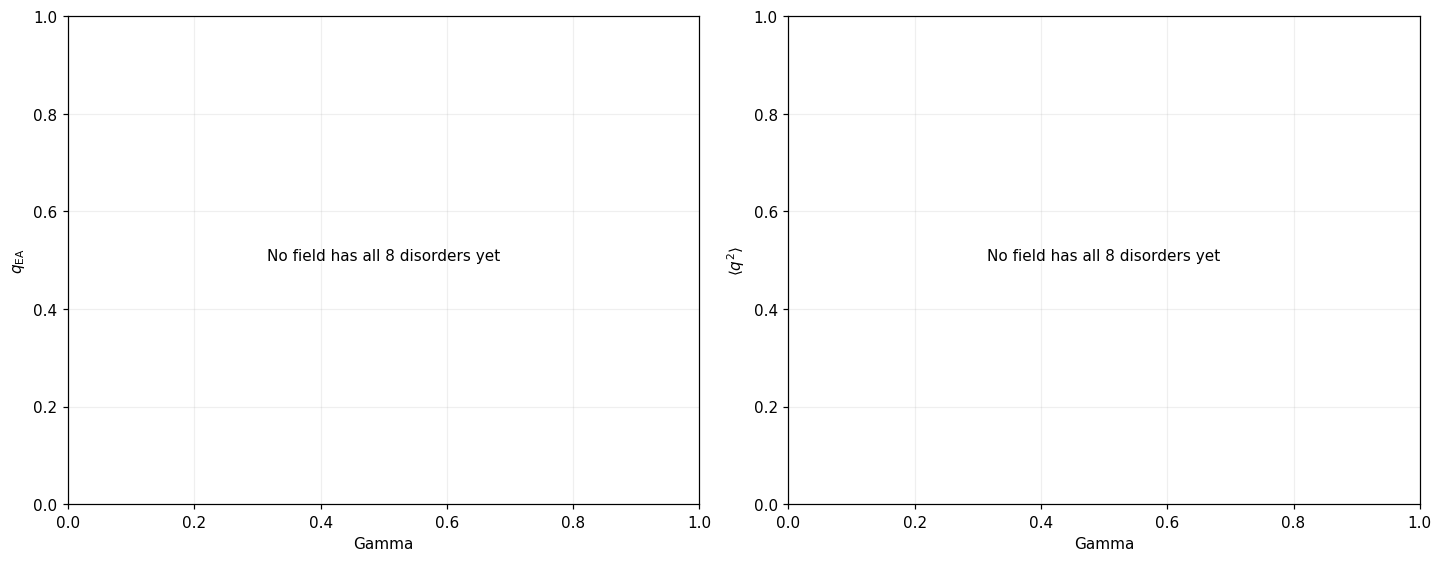

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for ax,key,label in zip(axes,['q_ea_finite','q2_raw'],[r'$q_{\rm EA}$',r'$\langle q^2\rangle$']):
    if summary['full_fields']:
        for seed in (0,1):
            for dim in (32,64,128):
                a=records[(records.seed==seed)&(records.D_MPS==dim)&records.gamma.isin(summary['full_fields'])]
                group=a.groupby('gamma')[key]
                mean=group.mean().reindex(gammas);sem=(group.std(ddof=1)/np.sqrt(8)).reindex(gammas)
                ax.plot(gammas,mean,color=colors[seed],ls=styles[dim],marker='.',label=f'start {seed}, D={dim}')
                ax.fill_between(gammas,mean-sem,mean+sem,color=colors[seed],alpha=.08)
    else:ax.text(.5,.5,'No field has all 8 disorders yet',ha='center',transform=ax.transAxes)
    ax.set(xlabel='Gamma',ylabel=label);ax.grid(alpha=.2)
if summary['full_fields']:axes[0].legend(fontsize=8)
finish(fig,'04_matched_disorder_means')

## Direct evidence: differences relative to the original tolerances

For $q_{\rm EA}$ the absolute tolerance is 0.001. For $\langle q^2\rangle$ the symmetric relative tolerance is 0.005 along
the ladder and 0.01 between starts. Energy per spin uses $10^{-7}$ and $10^{-6}$ respectively.
Full qualification also requires connected susceptibility, structure factors, $R$, last-sweep energy, canonical error,
and no current/prior truncation alarm. The complete tolerance table is in the D64 notebook.

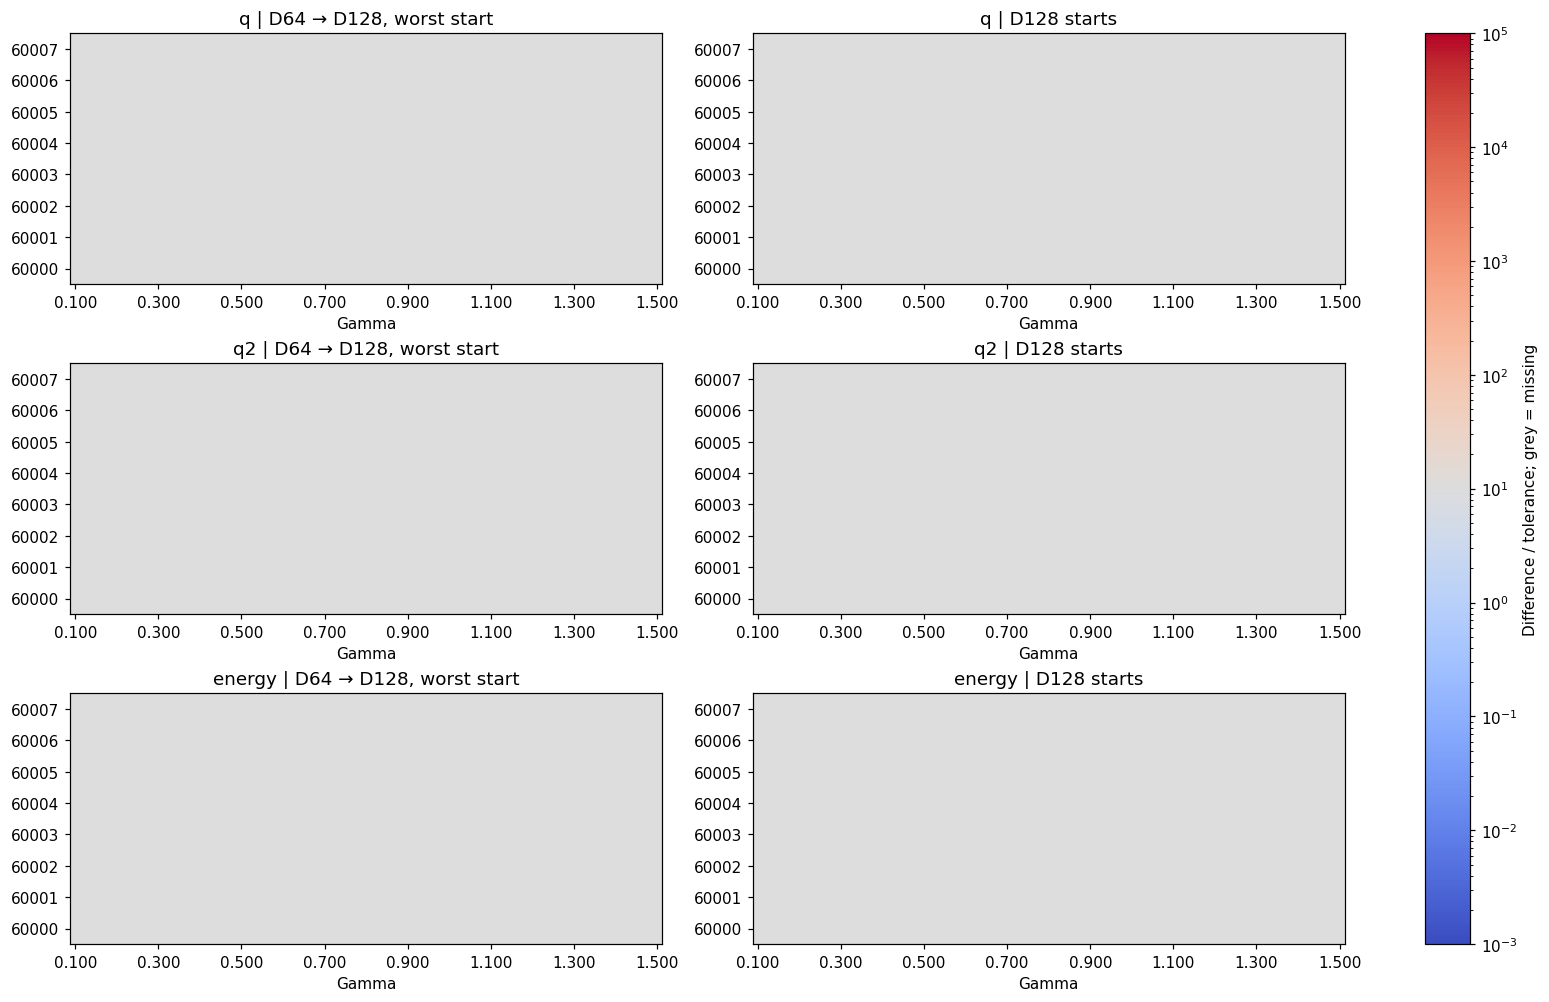

In [5]:
fig,axes=plt.subplots(3,2,figsize=(14,9),layout='constrained')
for row,key in enumerate(['q','q2','energy']):
    for col,kind in enumerate(['ladder','starts']):
        values=pd.DataFrame(np.nan,index=ids,columns=gammas)
        if len(comparisons):
            a=comparisons[comparisons.kind==kind].groupby(['sample_id','gamma'])[key+'_ratio'].max()
            for (sid,g),v in a.items():values.loc[sid,g]=max(v,1e-3)
        cmap=plt.get_cmap('coolwarm').copy();cmap.set_bad('#dddddd')
        im=axes[row,col].imshow(values,aspect='auto',origin='lower',cmap=cmap,norm=LogNorm(1e-3,1e5))
        axes[row,col].set(title=key+' | '+('D64 → D128, worst start' if kind=='ladder' else 'D128 starts'),
            xticks=ticks,xticklabels=[f'{gammas[i]:.3f}' for i in ticks],yticks=range(8),yticklabels=ids,xlabel='Gamma')
fig.colorbar(im,ax=axes.ravel().tolist(),label='Difference / tolerance; grey = missing')
finish(fig,'05_tolerance_heatmaps')
if len(comparisons):
    for kind in ['ladder','starts']:
        display(Markdown('**'+kind+' — largest q_EA differences**'))
        display(comparisons[comparisons.kind==kind].nlargest(10,'q_delta')[['gamma','sample_id','seed','q_delta','q2_delta','energy_delta','failed_gates']])

## Has the next step reduced the drift?

Each point compares one matched start's absolute q_EA change in D32→D64 with its change in D64→D128.
Below the diagonal means reduced drift, which alone does not establish convergence. Additional optimization occurs at each stage.
Two starts may still agree on the same metastable state. Retention settings m and chi have not been qualified.

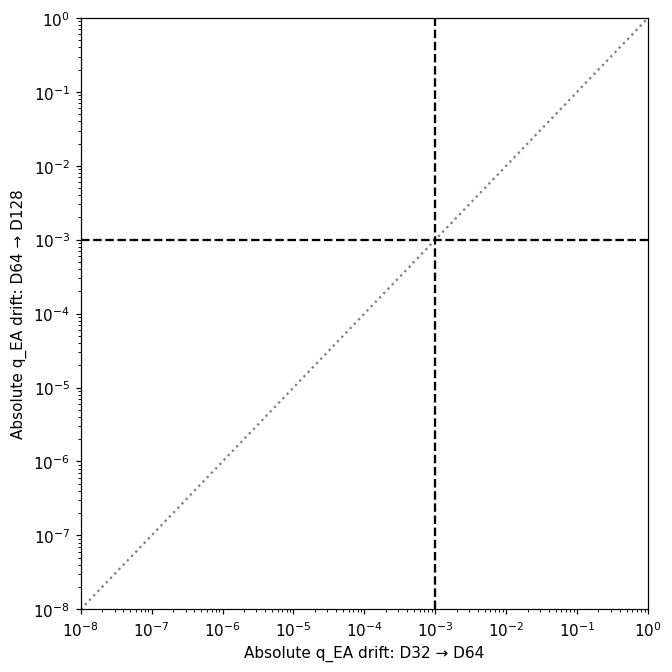

Physical moments are evaluated for the saved retained states. The notebook measures q_EA and q²; it does not reconstruct a sampled P(q). Full MPS checkpoints and optimizer diagnostics remain on AutoDL in losslessly compressed files.

In [6]:
fig,ax=plt.subplots(figsize=(6,6),layout='constrained')
for seed in (0,1):
    if len(records):
        a=records[records.seed==seed].pivot(index=['gamma','sample_id'],columns='D_MPS',values='q_ea_finite')
        ax.scatter(abs(a[64]-a[32]).clip(lower=1e-8),abs(a[128]-a[64]).clip(lower=1e-8),s=14,alpha=.6,color=colors[seed],label=f'start {seed}')
ax.plot([1e-8,1],[1e-8,1],color='grey',ls=':')
ax.axhline(.001,color='black',ls='--');ax.axvline(.001,color='black',ls='--')
ax.set(xscale='log',yscale='log',xlim=(1e-8,1),ylim=(1e-8,1),xlabel='Absolute q_EA drift: D32 → D64',ylabel='Absolute q_EA drift: D64 → D128')
if len(records):ax.legend()
finish(fig,'06_drift_reduction')
if len(cases):
    display(cases.groupby(['prior_solver_passed','solver_passed']).size().rename('Cases').to_frame())
display(Markdown('Physical moments are evaluated for the saved retained states. The notebook measures q_EA and q²; it does not reconstruct a sampled P(q). '
                 'Full MPS checkpoints and optimizer diagnostics remain on AutoDL in losslessly compressed files.'))